# Read the executed SigLIP2–DINOv2 comparison

This notebook reads the saved results of the 12-run exploratory follow-up. It performs
**no training, optimization, model downloading or test inference**. The reproduction
workflow is `model_comparison.ipynb`; its unexecuted status is separate from this reader.
The original DINOv2 test scores were known before this follow-up, so the test set is
reused. Treat comparisons as descriptive evidence under fixed settings.

[Current technical report](report/technical_report.pdf) ·
[Archived original DINOv2 report](report/archive/dinov2_study_2026-10-23/technical_report.pdf)

The newer model is not assumed to win. All tables below read the actual completed runs.


In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image, Markdown

candidates = [Path.cwd(), Path.cwd() / "beans_vit_project", Path.cwd() / "outputs/beans_vit_project"]
ROOT = next((path.resolve() for path in candidates
             if (path / "results/model_comparison/study_plan.json").is_file()), None)
if ROOT is None:
    raise RuntimeError("Open this notebook from the complete extracted project or repository.")
STUDY = ROOT / "results/model_comparison"
def read_json(path):
    return json.loads(Path(path).read_text(encoding="utf-8"))
completion = read_json(STUDY / "completion.json")
assert completion["status"] == "completed" and completion["run_count"] == 12
plan = read_json(STUDY / "study_plan.json")
analysis = read_json(STUDY / "comparison_analysis.json")
print("Completed:", completion["completed_utc"])
print("Run count:", completion["run_count"], "| Previous test exposure:", completion["prior_test_exposure"])
print(plan["study_status"])


Completed: 2026-10-24T06:33:59.261928+00:00
Run count: 12 | Previous test exposure: True
Exploratory follow-up after original DINOv2 test results were known; settings fixed before new training/evaluation


## Every run and the aggregate comparison

Accuracy and macro-F1 values are proportions; `*_pp` columns are percentage-point gaps.
Sample standard deviations describe three training seeds, not independent datasets.
Parameter counts, observed epoch times and peak allocated memory describe resource cost.
A low-resource fixed comparison does not measure the best achievable score of either model.

**Timing amendment:** during training, SigLIP2 frozen seed 17 epoch 9 took 809.10
seconds while its other epochs were about 13 seconds. The completed follow-up also
contains a 184.36-second training epoch (SigLIP2 partial seed 42, epoch 6), compared
with about 16 seconds for its other epochs. Both causes are unresolved.
Median, quartiles and range were added before the follow-up test evaluation to describe
the observed variation. The full run table and aggregate table retain raw training
totals and arithmetic means; neither long epoch was deleted or replaced. Median epoch
cost is descriptive of this execution, not a controlled speed or throughput comparison.
Pooled medians include every epoch, so seeds completing more epochs receive more weight.
Read the [recorded timing amendment](results/model_comparison/timing_analysis_amendment.json)
for the dated decision and the original frozen-epoch observation that motivated it.
That historical amendment is unchanged; the later partial-epoch observation is
disclosed here from the completed run's saved history.


,model,arm,seed,n_test,accuracy,macro_f1,best_epoch,epochs_completed,training_seconds,wall_seconds,...,train_loss,validation_accuracy,validation_macro_f1,validation_loss,test_accuracy,test_macro_f1,test_loss,train_minus_validation_f1_pp,train_minus_test_f1_pp,validation_minus_train_loss
0,dinov2,frozen,17,128,0.898438,0.899319,9,10,125.290025,146.362187,...,0.122156,0.954887,0.955220,0.122580,0.898438,0.899319,0.170623,0.041949,5.632052,0.000424
1,dinov2,frozen,42,128,0.890625,0.891644,2,5,66.027359,80.036629,...,0.225698,0.909774,0.910128,0.303081,0.890625,0.891644,0.246114,0.270441,2.118906,0.077384
2,dinov2,frozen,2026,128,0.929688,0.930424,10,10,117.059990,136.842208,...,0.124957,0.954887,0.954992,0.144663,0.929688,0.930424,0.188282,0.452201,2.908951,0.019707
3,dinov2,partial,17,128,0.984375,0.984487,3,6,79.709975,94.218943,...,0.076927,0.977444,0.977664,0.062764,0.984375,0.984487,0.062270,0.689738,0.007472,-0.014164
4,dinov2,partial,42,128,0.953125,0.953571,5,8,103.174270,119.667332,...,0.090560,0.984962,0.985017,0.047729,0.953125,0.953571,0.102553,-0.522778,2.621802,-0.042830
5,dinov2,partial,2026,128,0.968750,0.968875,6,9,105.828029,122.812642,...,0.085593,0.992481,0.992509,0.020328,0.968750,0.968875,0.076740,-1.174135,1.189305,-0.065265
6,siglip2,frozen,17,128,0.984375,0.984488,10,10,930.012516,957.331361,...,0.150710,0.954887,0.955255,0.114987,0.984375,0.984488,0.117687,-0.710802,-3.634083,-0.035723
7,siglip2,frozen,42,128,0.960938,0.961235,5,8,103.592955,123.344251,...,0.200755,0.954887,0.954914,0.157254,0.960938,0.961235,0.160107,-1.835382,-2.467501,-0.043502
8,siglip2,frozen,2026,128,0.960938,0.961193,9,10,128.896846,152.412764,...,0.152522,0.962406,0.962471,0.113423,0.960938,0.961193,0.121501,-1.452888,-1.325096,-0.039099
9,siglip2,partial,17,128,0.976562,0.976716,6,9,147.311193,168.839884,...,0.031848,0.984962,0.985002,0.061811,0.976562,0.976716,0.063690,0.825696,1.654279,0.029963


,model,arm,runs,accuracy_mean,accuracy_sd,macro_f1_mean,macro_f1_sd,training_seconds_mean,training_seconds_sd,mean_training_epoch_seconds_mean,...,pooled_training_seconds_per_epoch,trainable_params,total_params,peak_cuda_allocated_bytes_max,pooled_epoch_median_seconds,pooled_epoch_q1_seconds,pooled_epoch_q3_seconds,pooled_epoch_iqr_seconds,pooled_epoch_min_seconds,pooled_epoch_max_seconds
0,dinov2,frozen,3,0.90625,0.020670,0.907129,0.020536,102.792458,32.104326,12.480158,...,12.335095,1155,22057731,191755264,11.935021,11.762332,12.684340,0.922009,11.493755,14.082333
1,dinov2,partial,3,0.96875,0.015625,0.968978,0.015458,96.237425,14.374563,12.646816,...,12.552708,3552387,22057731,287726592,12.624520,11.838451,13.058367,1.219916,11.517730,13.959295
2,siglip2,frozen,3,0.96875,0.013532,0.968972,0.013437,387.500772,469.999272,39.613352,...,41.517940,2307,92886531,482041344,12.985640,12.885871,13.319275,0.433403,12.668928,809.095732
3,siglip2,partial,3,0.96875,0.007812,0.968989,0.007767,195.884808,73.334397,24.137527,...,22.602093,14179587,92886531,722230272,16.083046,15.974964,16.352793,0.377829,15.617464,184.364705


**Descriptive observed epoch cost, retaining total training time**

,model,arm,pooled_epochs,pooled_epoch_median_seconds,pooled_epoch_q1_seconds,pooled_epoch_q3_seconds,pooled_epoch_iqr_seconds,pooled_epoch_min_seconds,pooled_epoch_max_seconds,pooled_training_seconds,pooled_training_seconds_per_epoch,training_seconds_mean
0,dinov2,frozen,25,11.935021,11.762332,12.684340,0.922009,11.493755,14.082333,308.377374,12.335095,102.792458
1,dinov2,partial,23,12.624520,11.838451,13.058367,1.219916,11.517730,13.959295,288.712274,12.552708,96.237425
2,siglip2,frozen,28,12.985640,12.885871,13.319275,0.433403,12.668928,809.095732,1162.502317,41.517940,387.500772
3,siglip2,partial,26,16.083046,15.974964,16.352793,0.377829,15.617464,184.364705,587.654424,22.602093,195.884808


Timing interpretation: Descriptive measured durations, not corrected hardware benchmarks. Different completed epoch counts weight seeds differently in pooled epoch summaries; raw run totals, run means and pooled means remain reported. No cause is assigned to unusually long epochs.
Timing amendment recorded: 2026-10-24T05:58:39.0055066Z


,arm,seed,dinov2_macro_f1,siglip2_macro_f1,siglip2_minus_dinov2_macro_f1,dinov2_accuracy,siglip2_accuracy,siglip2_minus_dinov2_accuracy
0,frozen,17,0.899319,0.984488,0.085169,0.898438,0.984375,0.085938
1,frozen,42,0.891644,0.961235,0.069591,0.890625,0.960938,0.070312
2,frozen,2026,0.930424,0.961193,0.030769,0.929688,0.960938,0.031250
3,partial,17,0.984487,0.976716,-0.007771,0.984375,0.976562,-0.007812
4,partial,42,0.953571,0.969068,0.015497,0.953125,0.968750,0.015625
5,partial,2026,0.968875,0.961182,-0.007693,0.968750,0.960938,-0.007812


{
  "ci95_percentile": [
    -0.0313437134008446,
    0.01570583887657051
  ],
  "resamples": 2000,
  "seed": 20261023,
  "method": "paired class-stratified percentile bootstrap",
  "limitation": "Conditional on observed classes and independent audited images; unknown plant/farm dependence is not corrected.",
  "difference_siglip2_minus_dinov2": -0.007770757367027481,
  "arm": "partial",
  "reference_seed": 17,
  "scope": "Descriptive interval for the seed-17 model pair on the previously evaluated test split; not an interval for the three-seed mean or a fresh confirmatory test."
}


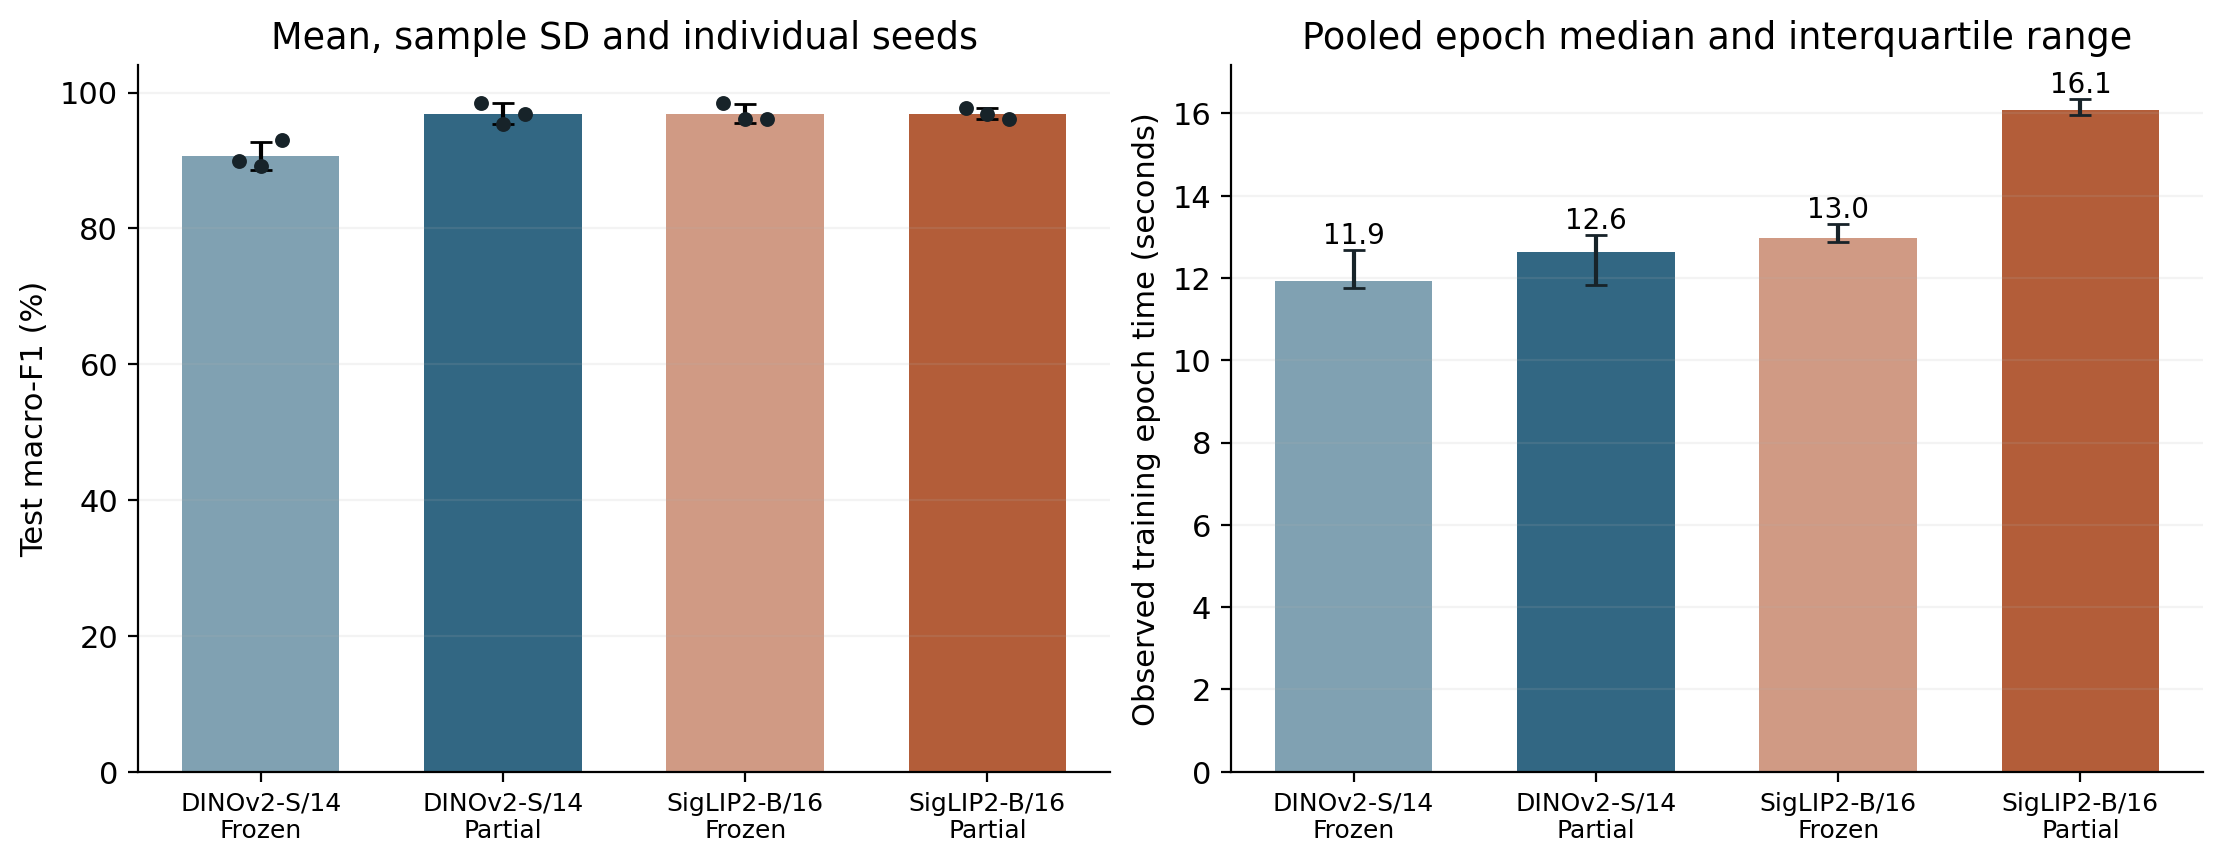

In [2]:
runs = pd.read_csv(STUDY / "combined_run_metrics.csv")
assert len(runs) == 12
assert set(runs["model"]) == {"dinov2", "siglip2"}
assert set(runs["arm"]) == {"frozen", "partial"}
assert set(runs["seed"]) == {17, 42, 2026}
display(runs)
summary = pd.read_csv(STUDY / "combined_summary.csv")
display(summary)
timing_columns = ["model", "arm", "pooled_epochs", "pooled_epoch_median_seconds",
                  "pooled_epoch_q1_seconds", "pooled_epoch_q3_seconds", "pooled_epoch_iqr_seconds",
                  "pooled_epoch_min_seconds", "pooled_epoch_max_seconds", "pooled_training_seconds",
                  "pooled_training_seconds_per_epoch", "training_seconds_mean"]
display(Markdown("**Descriptive observed epoch cost, retaining total training time**"))
display(summary[timing_columns])
timing = analysis["timing_analysis"]
assert timing["raw_times_preserved"] is True
assert timing["amendment"]["before_new_test_evaluation"] is True
print("Timing interpretation:", timing["interpretation"])
print("Timing amendment recorded:", timing["amendment"]["created_utc"])
display(pd.read_csv(STUDY / "paired_model_differences.csv"))
print(json.dumps(analysis["primary_comparison"], indent=2))
display(Image(filename=str(STUDY / "figures/performance_cost.png"), width=1000))


## Class errors and real sample outputs

These are reference seed-17 outputs. Confidence scores are uncalibrated softmax values;
a confident error can still occur. The bootstrap comparison is conditional on this
reference pair and this small reused test sample. It does not establish independent
farm-level or external-field superiority.


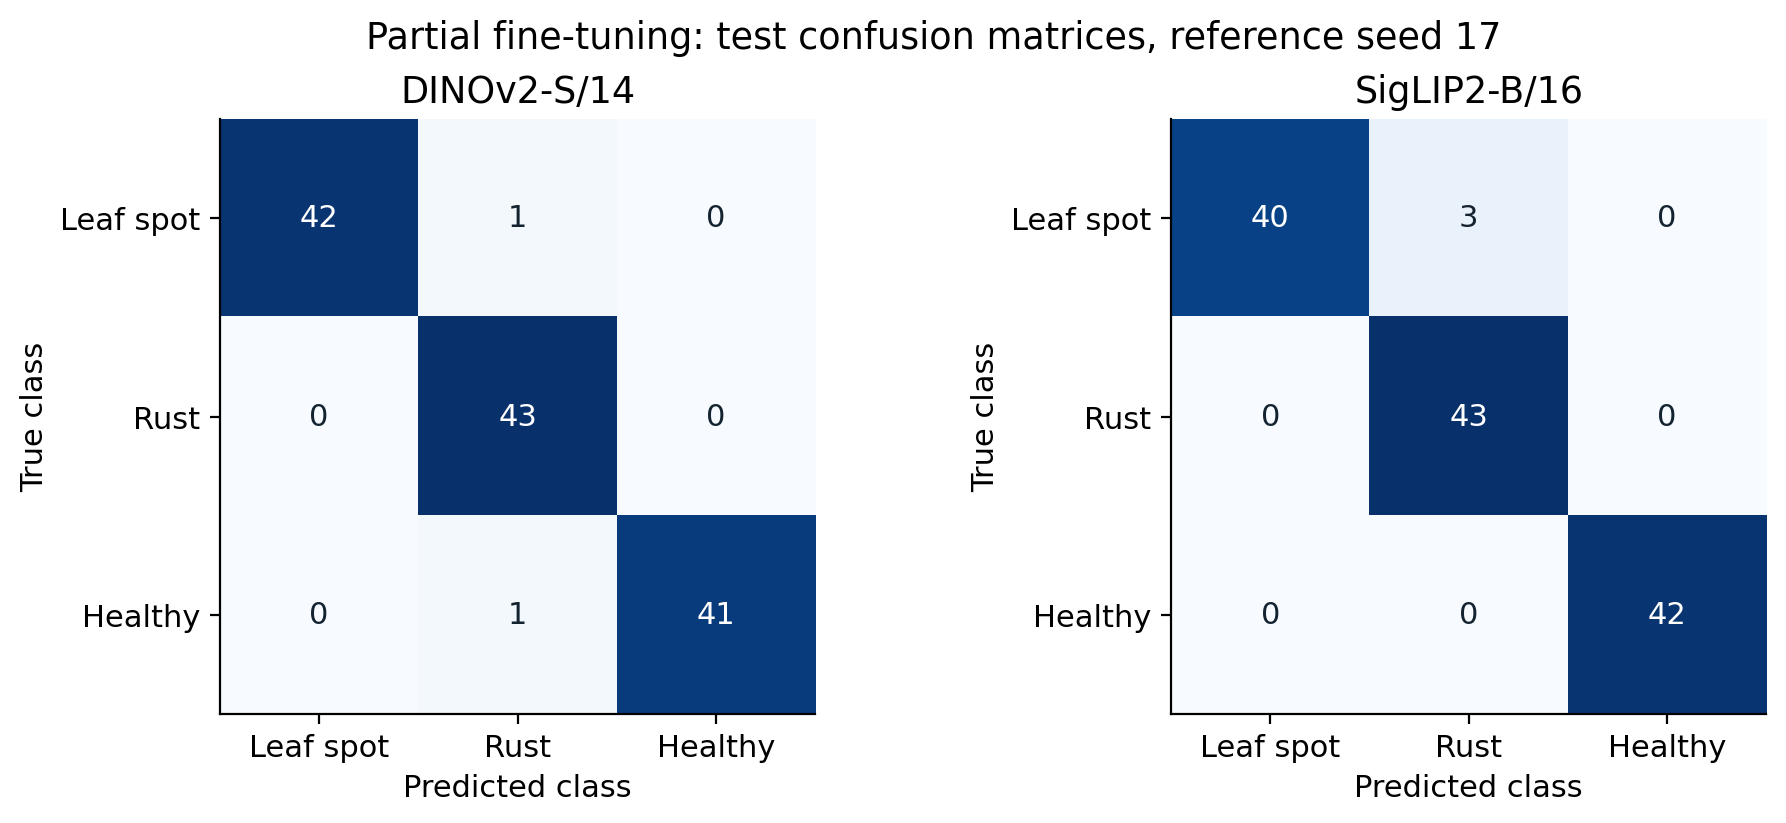

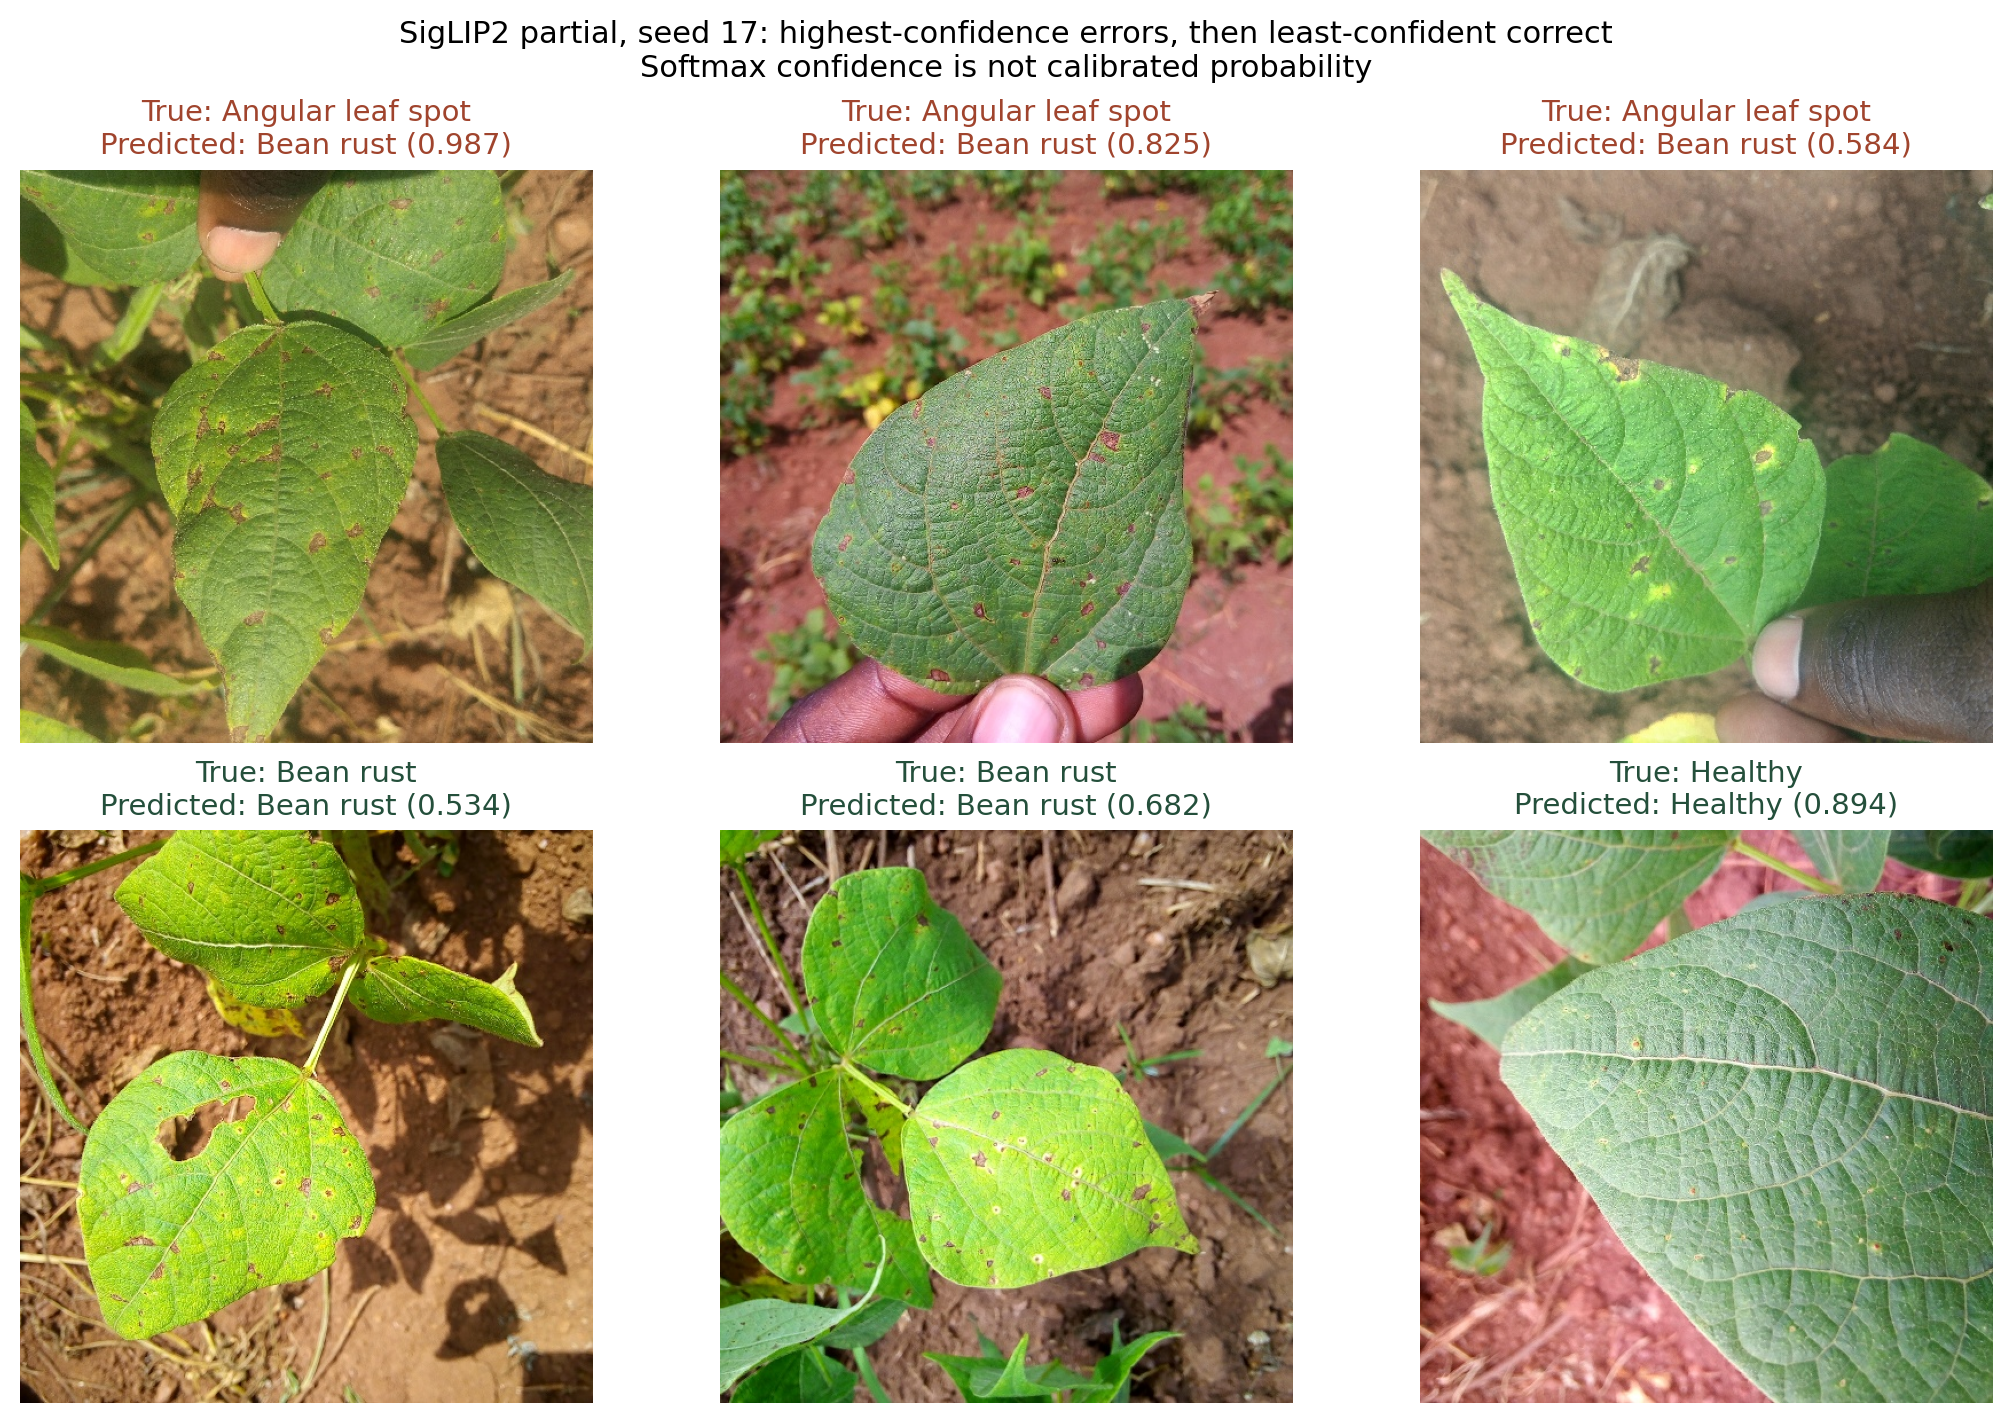

### dinov2 class metrics and synthetic sensitivity

,arm,seed,class,precision,recall,f1-score,support
0,frozen,17,Angular leaf spot,0.886364,0.906977,0.896552,43.0
1,frozen,17,Bean rust,0.847826,0.906977,0.876404,43.0
2,frozen,17,Healthy,0.973684,0.880952,0.925000,42.0
3,partial,17,Angular leaf spot,1.000000,0.976744,0.988235,43.0
4,partial,17,Bean rust,0.955556,1.000000,0.977273,43.0
5,partial,17,Healthy,1.000000,0.976190,0.987952,42.0


,arm,seed,condition,accuracy,macro_f1,diseased_as_healthy
0,frozen,17,clean,0.898438,0.899319,1
1,frozen,17,blur,0.921875,0.922453,0
2,frozen,17,brightness,0.921875,0.922453,0
3,partial,17,clean,0.984375,0.984487,0
4,partial,17,blur,0.976562,0.976738,0
5,partial,17,brightness,0.984375,0.984487,0


### siglip2 class metrics and synthetic sensitivity

,arm,seed,class,precision,recall,f1-score,support
0,frozen,17,Angular leaf spot,1.000000,0.953488,0.976190,43.0
1,frozen,17,Bean rust,0.955556,1.000000,0.977273,43.0
2,frozen,17,Healthy,1.000000,1.000000,1.000000,42.0
3,partial,17,Angular leaf spot,1.000000,0.930233,0.963855,43.0
4,partial,17,Bean rust,0.934783,1.000000,0.966292,43.0
5,partial,17,Healthy,1.000000,1.000000,1.000000,42.0


,arm,seed,condition,accuracy,macro_f1,diseased_as_healthy
0,frozen,17,clean,0.984375,0.984488,0
1,frozen,17,blur,0.945312,0.945131,2
2,frozen,17,brightness,0.984375,0.984496,0
3,partial,17,clean,0.976562,0.976716,0
4,partial,17,blur,0.960938,0.960687,1
5,partial,17,brightness,0.976562,0.976741,0


In [3]:
display(Image(filename=str(STUDY / "figures/partial_confusion.png"), width=1000))
display(Image(filename=str(STUDY / "figures/siglip_sample_predictions.png"), width=1000))
for model in ["dinov2", "siglip2"]:
    display(Markdown("### " + model + " class metrics and synthetic sensitivity"))
    display(pd.read_csv(STUDY / model / "per_class_metrics.csv"))
    display(pd.read_csv(STUDY / model / "stress_metrics.csv"))


## Overfitting diagnostics for every selected checkpoint

Clean training and validation metrics use identical deterministic preprocessing and
evaluation mode with each fixed checkpoint. Test metrics are reused from the recorded
evaluations. All histories are included because later validation deterioration can be
hidden by inspecting only the selected epoch. Online augmented training loss is not
directly equivalent to a fixed-checkpoint clean loss. Small average gaps do not prove
absence of overfitting, data dependence or distribution shift.


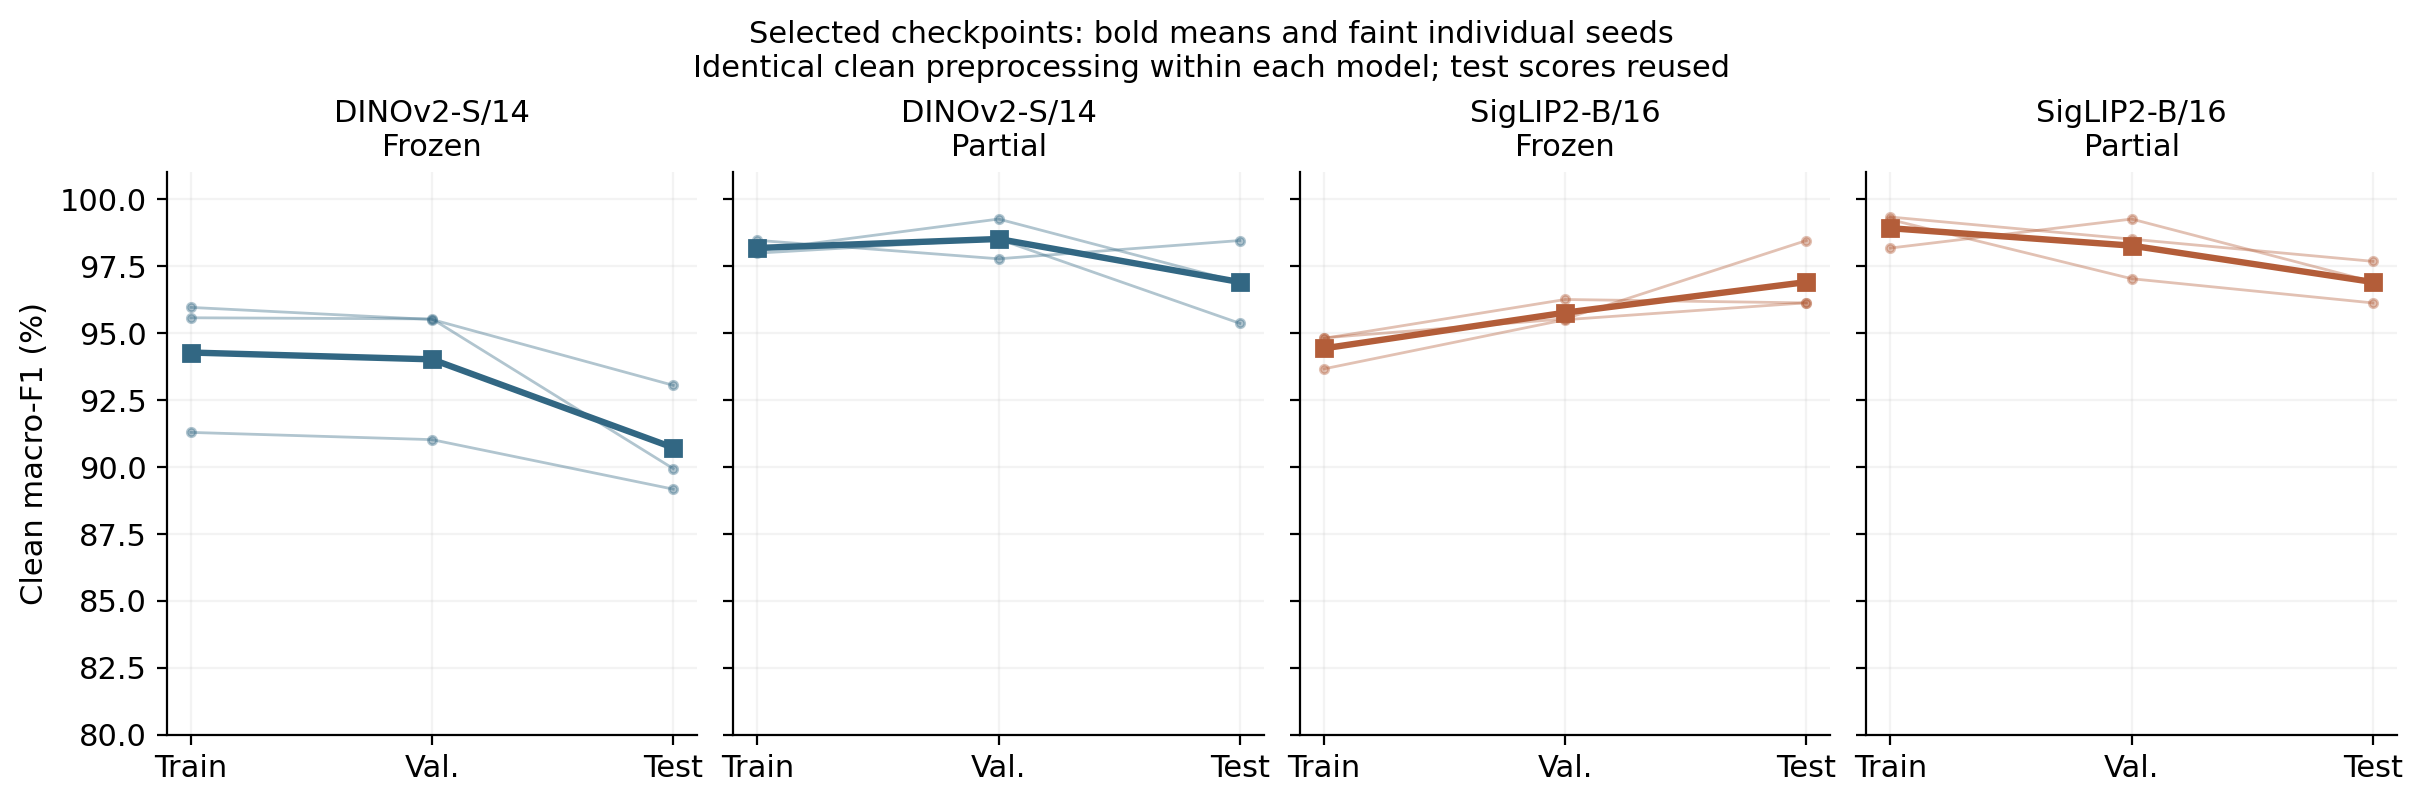

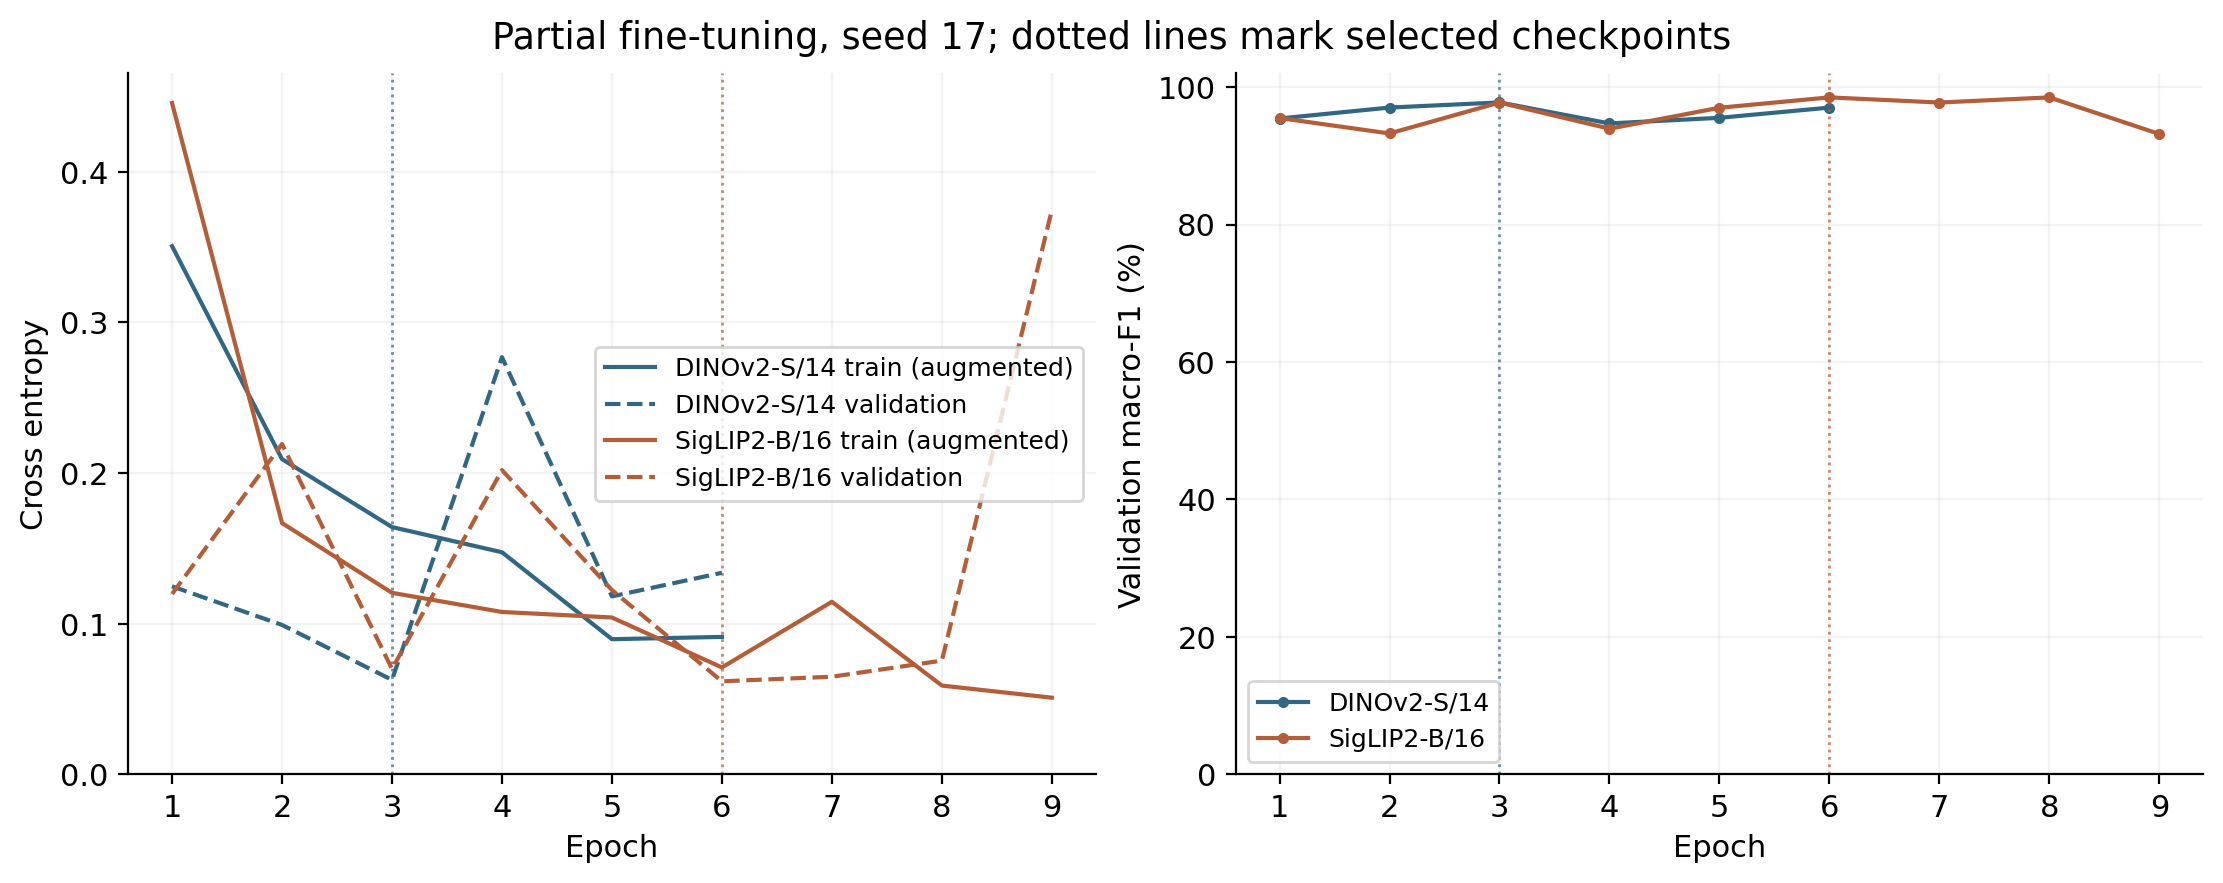

### dinov2 clean checkpoint metrics and all-seed trajectories

,arm,runs,train_macro_f1_mean,validation_macro_f1_mean,test_macro_f1_mean,train_accuracy_mean,validation_accuracy_mean,train_loss_mean,validation_loss_mean,train_minus_validation_f1_pp_mean,train_minus_test_f1_pp_mean
0,frozen,3,0.942662,0.940113,0.907129,0.942618,0.939850,0.157603,0.190108,0.254864,3.553303
1,partial,3,0.981706,0.985063,0.968978,0.981625,0.984962,0.084360,0.043607,-0.335725,1.272860


,arm,seed,selected_epoch,train_n,train_accuracy,train_macro_f1,train_loss,validation_n,validation_accuracy,validation_macro_f1,validation_loss,test_n,test_accuracy,test_macro_f1,test_loss,train_minus_validation_f1_pp,train_minus_test_f1_pp,validation_minus_train_loss
0,frozen,17,9,1034,0.955513,0.955639,0.122156,133,0.954887,0.955220,0.122580,128,0.898438,0.899319,0.170623,0.041949,5.632052,0.000424
1,frozen,42,2,1034,0.912959,0.912833,0.225698,133,0.909774,0.910128,0.303081,128,0.890625,0.891644,0.246114,0.270441,2.118906,0.077384
2,frozen,2026,10,1034,0.959381,0.959514,0.124957,133,0.954887,0.954992,0.144663,128,0.929688,0.930424,0.188282,0.452201,2.908951,0.019707
3,partial,17,3,1034,0.984526,0.984561,0.076927,133,0.977444,0.977664,0.062764,128,0.984375,0.984487,0.062270,0.689738,0.007472,-0.014164
4,partial,42,5,1034,0.979691,0.979789,0.090560,133,0.984962,0.985017,0.047729,128,0.953125,0.953571,0.102553,-0.522778,2.621802,-0.042830
5,partial,2026,6,1034,0.980658,0.980768,0.085593,133,0.992481,0.992509,0.020328,128,0.968750,0.968875,0.076740,-1.174135,1.189305,-0.065265


,arm,seed,selected_epoch,final_epoch,selected_validation_loss,final_validation_loss,final_minus_selected_validation_loss,selected_minus_final_validation_f1_pp,post_selection_epochs,post_selection_epochs_with_higher_validation_loss,final_minus_selected_augmented_training_loss
0,frozen,17,9,10,0.122580,0.151110,0.028530,0.749064,1,1,-0.016528
1,frozen,42,2,5,0.303081,0.225457,-0.077624,1.628126,3,1,-0.111993
2,frozen,2026,10,10,0.144663,0.144663,0.000000,0.000000,0,0,0.000000
3,partial,17,3,6,0.062764,0.133859,0.071096,0.748441,3,3,-0.072900
4,partial,42,5,8,0.047729,0.082983,0.035253,0.750010,3,3,0.001001
5,partial,2026,6,9,0.020328,0.024844,0.004516,0.750768,3,3,-0.029318


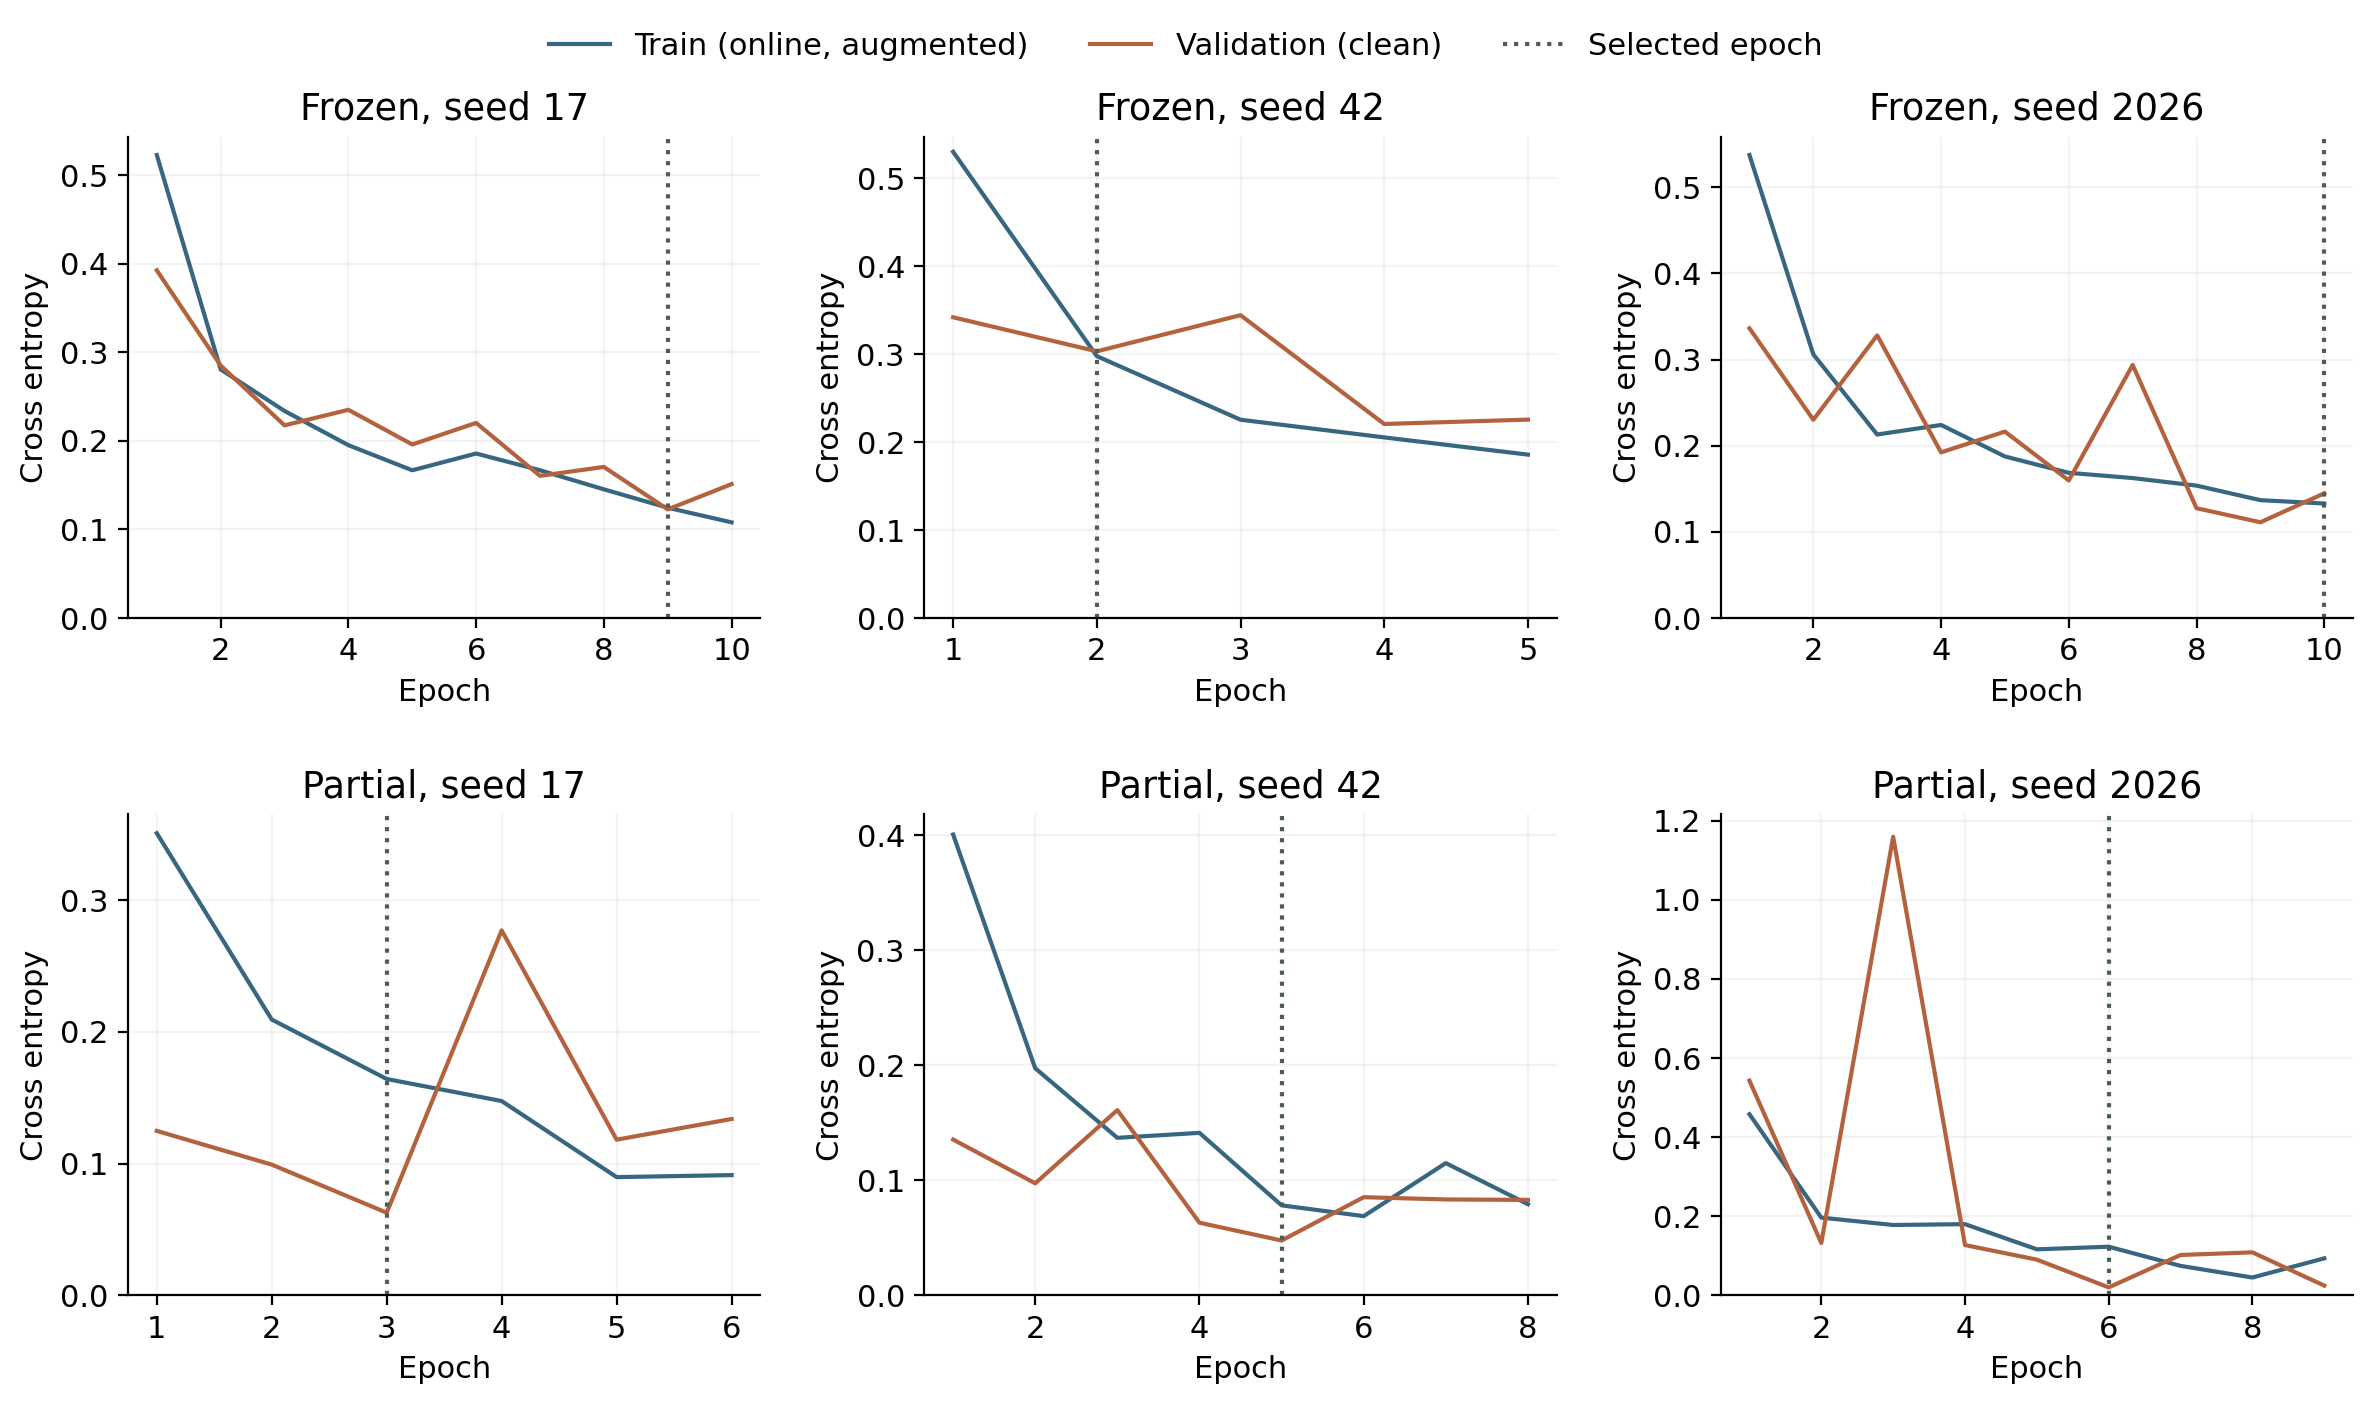

### siglip2 clean checkpoint metrics and all-seed trajectories

,arm,runs,train_macro_f1_mean,validation_macro_f1_mean,test_macro_f1_mean,train_accuracy_mean,validation_accuracy_mean,train_loss_mean,validation_loss_mean,train_minus_validation_f1_pp_mean,train_minus_test_f1_pp_mean
0,frozen,3,0.944216,0.957547,0.968972,0.943907,0.957393,0.167996,0.128554,-1.333024,-2.475560
1,partial,3,0.989078,0.982576,0.968989,0.989039,0.982456,0.040254,0.066344,0.650258,2.008961


,arm,seed,selected_epoch,train_n,train_accuracy,train_macro_f1,train_loss,validation_n,validation_accuracy,validation_macro_f1,validation_loss,test_n,test_accuracy,test_macro_f1,test_loss,train_minus_validation_f1_pp,train_minus_test_f1_pp,validation_minus_train_loss
0,frozen,17,10,1034,0.947776,0.948147,0.150710,133,0.954887,0.955255,0.114987,128,0.984375,0.984488,0.117687,-0.710802,-3.634083,-0.035723
1,frozen,42,5,1034,0.936170,0.936560,0.200755,133,0.954887,0.954914,0.157254,128,0.960938,0.961235,0.160107,-1.835382,-2.467501,-0.043502
2,frozen,2026,9,1034,0.947776,0.947942,0.152522,133,0.962406,0.962471,0.113423,128,0.960938,0.961193,0.121501,-1.452888,-1.325096,-0.039099
3,partial,17,6,1034,0.993230,0.993259,0.031848,133,0.984962,0.985002,0.061811,128,0.976562,0.976716,0.063690,0.825696,1.654279,0.029963
4,partial,42,4,1034,0.981625,0.981683,0.059336,133,0.992481,0.992506,0.018278,128,0.968750,0.969068,0.071354,-1.082242,1.261544,-0.041058
5,partial,2026,8,1034,0.992263,0.992293,0.029577,133,0.969925,0.970219,0.118944,128,0.960938,0.961182,0.221132,2.207321,3.111060,0.089367


,arm,seed,selected_epoch,final_epoch,selected_validation_loss,final_validation_loss,final_minus_selected_validation_loss,selected_minus_final_validation_f1_pp,post_selection_epochs,post_selection_epochs_with_higher_validation_loss,final_minus_selected_augmented_training_loss
0,frozen,17,10,10,0.114987,0.114987,0.000000,0.000000,0,0,0.000000
1,frozen,42,5,8,0.157254,0.165734,0.008480,0.680112,3,2,-0.045127
2,frozen,2026,9,10,0.113423,0.123997,0.010575,1.467335,1,1,-0.004772
3,partial,17,6,9,0.061811,0.374607,0.312796,5.327940,3,3,-0.020094
4,partial,42,4,7,0.018278,0.210090,0.191812,3.772916,3,3,-0.019219
5,partial,2026,8,10,0.118944,0.131077,0.012133,0.027689,2,2,-0.017772


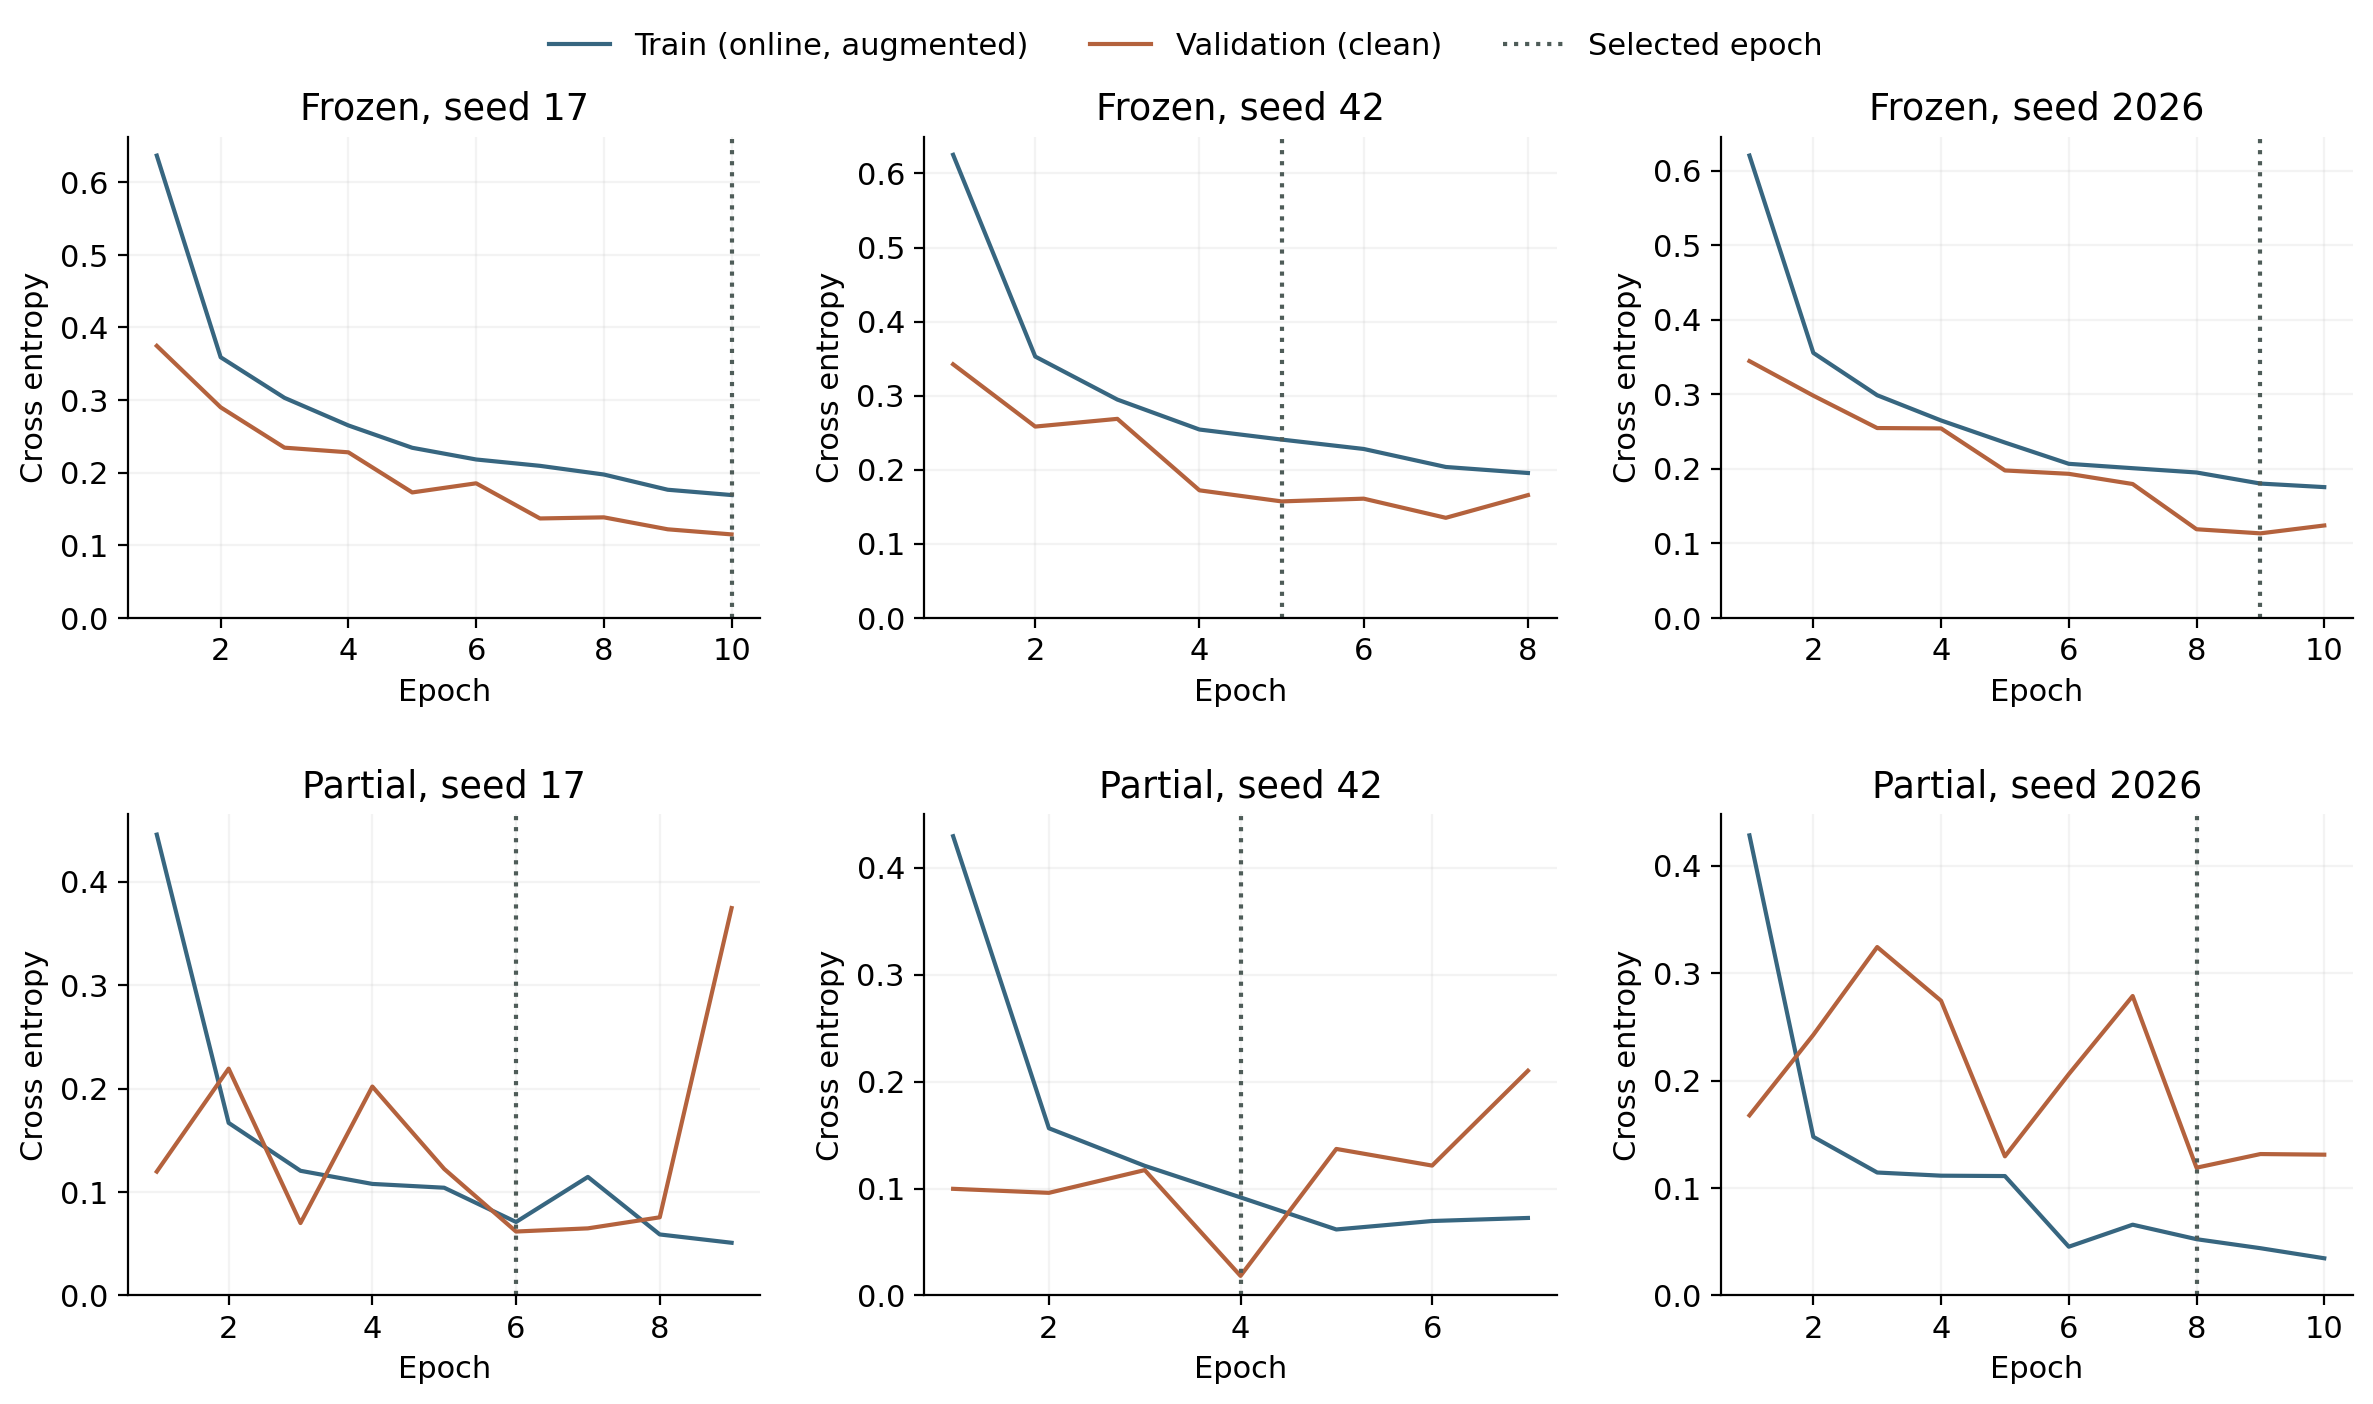

In [4]:
display(Image(filename=str(STUDY / "figures/model_generalisation.png"), width=1000))
display(Image(filename=str(STUDY / "figures/reference_learning_curves.png"), width=1000))
for model in ["dinov2", "siglip2"]:
    display(Markdown("### " + model + " clean checkpoint metrics and all-seed trajectories"))
    folder = STUDY / model / "overfitting"
    audit = read_json(folder / "audit.json")
    assert audit["optimization_performed"] is False
    assert audit["new_test_evaluation_performed"] is False
    assert audit["validation_predictions_match_original"] is True
    display(pd.read_csv(folder / "summary.csv"))
    display(pd.read_csv(folder / "checkpoint_gaps.csv"))
    display(pd.read_csv(folder / "history_diagnostics.csv"))
    display(Image(filename=str(folder / "all_seed_learning_curves.png"), width=1000))


## Interpretation and provenance

The plan was fixed before this follow-up's training/evaluation, while the original
study's test results were already known. Both backbones were retrained. Model families
differ in size, pretraining, image readout and native preprocessing, so the experiment
does not isolate the causal effect of model age. SigLIP2 is a newer competitive family;
being newer does not itself guarantee better Beans performance. The formal technical
report explains dataset limits, treatment consequences and responsible use.


In [5]:
for item in analysis["interpretation_limits"]:
    print("-", item)
print("Study plan SHA256:", completion["study_plan_sha256"])
print("Training source SHA256:", completion["training_source_sha256"])
print("This notebook displayed saved evidence; no model was trained or evaluated here.")


- Exploratory follow-up: the original DINOv2 test results were known before this study; the reused test split is not fresh confirmatory evidence.
- Model sizes, pretraining data, pooling and native preprocessing differ; the comparison does not isolate model age or pretraining objective.
- Fixed learning rates and adaptation depth were not separately optimised for each model.
- Three training seeds describe limited optimisation variability, not independent datasets or external population uncertainty.
- Unknown plant/farm dependence and pretraining overlap remain; no external dataset establishes geographic or field generalisation.
- A recent competitive model family does not establish the newest or best model in October 2026, or state-of-the-art performance on Beans.
- Clean training/validation diagnostics reuse development data; a small gap does not prove absence of overfitting.
Study plan SHA256: afaa8f66d972f829d10410cac3cec5a0554051cbbe6c32feda11582c5e45164b
Training source SHA256: b